# Showcase - match visualisations

Every chart in `wyscout.reports.match`, with its variations, on Southend United's most recent
match. Each section names the function, what it shows and which arguments change it. The
charts are built from two layers you can also use directly: `wyscout.data` turns API
responses into events, locations and tables; `wyscout.viz` draws them. The last section shows
that.

## Setup

Reload the `wyscout` package on every cell so edits to it are picked up without restarting the kernel, then load the API credentials and point at the local cache. Nothing here produces output.

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import os
from dotenv import load_dotenv

load_dotenv()  # CLIENT_ID and CLIENT_SECRET for the Wyscout API, from notebooks/.env
os.environ.setdefault("MONGO_HOST", "localhost")  # every API response is cached in Mongo

import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 160)

## The match

Charts take a Wyscout match id. `season_events` lists the league matches whose events have
been published, newest first; the default here is the latest, and `OTHER_MATCH` the one before
it for the side-by-side examples.

In [3]:
from wyscout.ids import SOUTHEND, SEASON_2026, H_CARDWELL, L_CHAMBERS_PARILLON
from wyscout.data.season import season_events
from wyscout.reports import match

SEASON = SEASON_2026
available = season_events(SOUTHEND, SEASON, oldest_first=False)
for m in available[:5]:
    print(m["summary"].match_id, m["summary"].title())

MATCH_ID = available[0]["summary"].match_id
OTHER_MATCH = available[1]["summary"].match_id

5864944 Tamworth (H), 15 Sep, 2026, W 3-1
5864938 Carlisle United (A), 12 Sep, 2026, D 2-2
5864917 Yeovil Town (H), 05 Sep, 2026, W 3-2
5864912 Woking (A), 31 Aug, 2026, D 1-1
5864900 Kidderminster Harriers (H), 28 Aug, 2026, L 1-3


## `action_map` - touches and attempts

A heat map of where the team touched the ball with the attempts drawn on top (area is xG, red
ring is a goal, darker blue is on target).

| argument | effect |
|---|---|
| `split_halves` | one pitch per half (default) or the whole match |
| `show_oppo_shots` | the opposition's attempts in grey at our end |
| `player_id` | only that player's touches |
| `passes_received_by` | arrows for passes to that player, red if the move produced a goal |
| `subtitle`, `cmap`, `shot_colors`, `fig_height` | presentation |

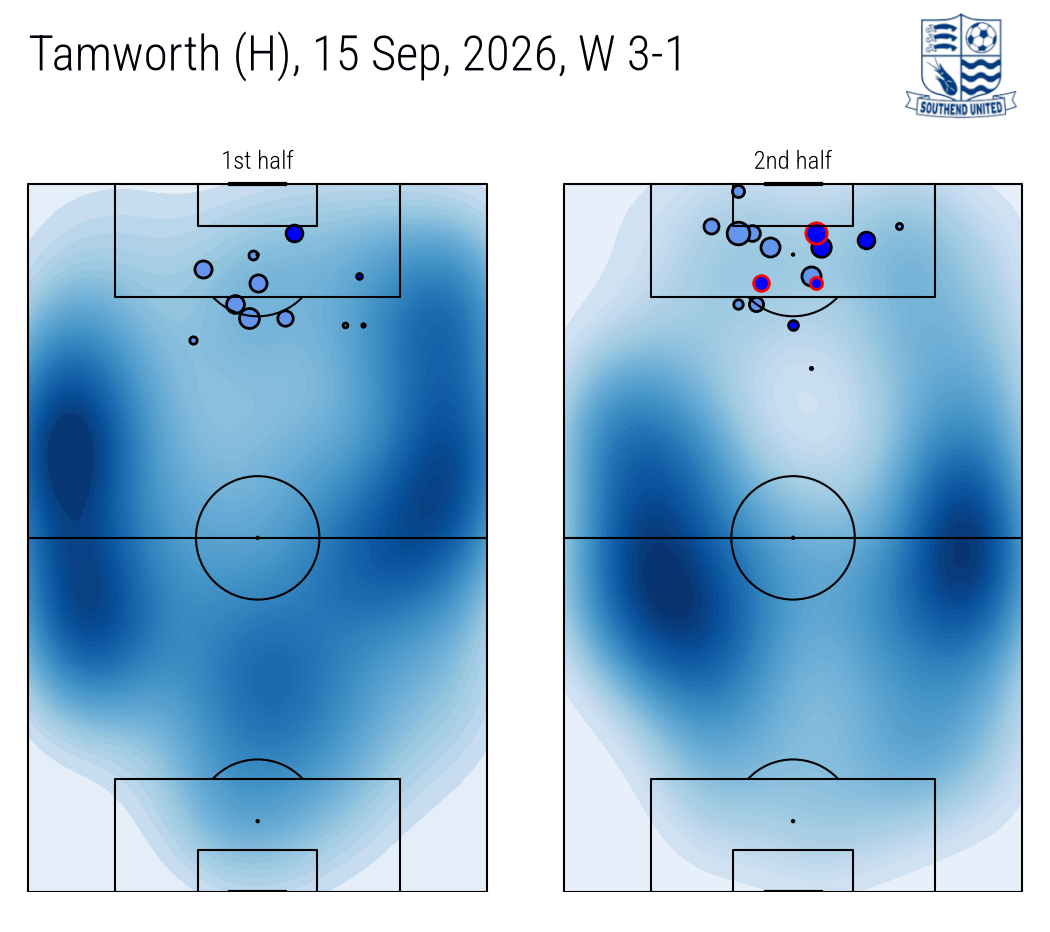

(<Figure size 1171.32x1000 with 5 Axes>,
 {'pitch': array([<Axes: >, <Axes: >], dtype=object),
  'title': <Axes: >,
  'endnote': <Axes: >},
 VerticalPitch(pitch_type='wyscout', half=False, pitch_color='white', line_color='black', linewidth=1.5, line_zorder=2, linestyle=None, stripe=False, stripe_color='#c2d59d', stripe_zorder=0.6, pad_left=4, pad_right=4, pad_bottom=0.0, pad_top=12.952380952380954, positional=False, positional_zorder=0.8, positional_linewidth=1.5, positional_linestyle=None, positional_color='#eadddd', positional_alpha=1, shade_middle=False, shade_color='#f2f2f2', shade_alpha=1, shade_zorder=0.7, pitch_length=None, pitch_width=None, goal_type='line', goal_alpha=1, line_alpha=1, label=False, tick=False, axis=False, spot_scale=0.024, spot_type='circle'), corner_arcs=False))

In [4]:
match.action_map(SOUTHEND, MATCH_ID)

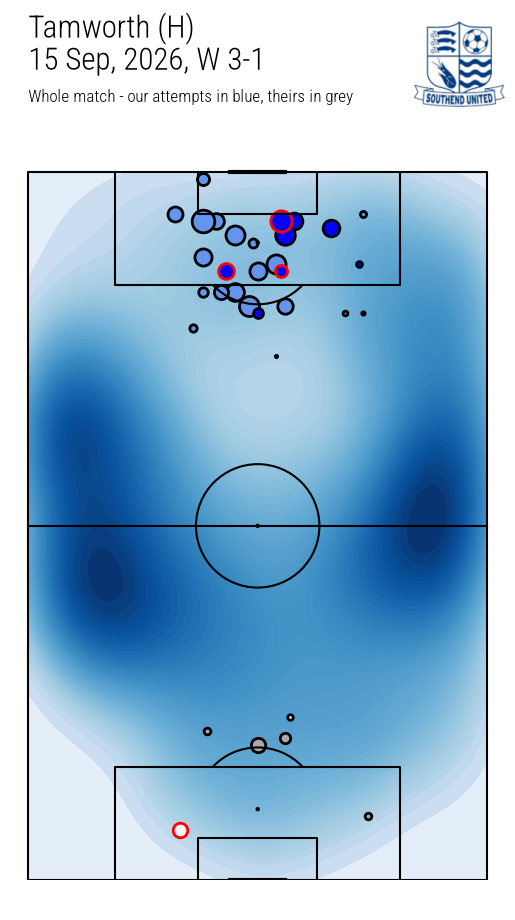

(<Figure size 562.931x1000 with 4 Axes>,
 {'pitch': <Axes: >, 'title': <Axes: >, 'endnote': <Axes: >},
 VerticalPitch(pitch_type='wyscout', half=False, pitch_color='white', line_color='black', linewidth=1.5, line_zorder=2, linestyle=None, stripe=False, stripe_color='#c2d59d', stripe_zorder=0.6, pad_left=4, pad_right=4, pad_bottom=0.0, pad_top=12.952380952380954, positional=False, positional_zorder=0.8, positional_linewidth=1.5, positional_linestyle=None, positional_color='#eadddd', positional_alpha=1, shade_middle=False, shade_color='#f2f2f2', shade_alpha=1, shade_zorder=0.7, pitch_length=None, pitch_width=None, goal_type='line', goal_alpha=1, line_alpha=1, label=False, tick=False, axis=False, spot_scale=0.024, spot_type='circle'), corner_arcs=False))

In [5]:
match.action_map(SOUTHEND, MATCH_ID, split_halves=False, show_oppo_shots=True,
                 subtitle=["Whole match - our attempts in blue, theirs in grey"])

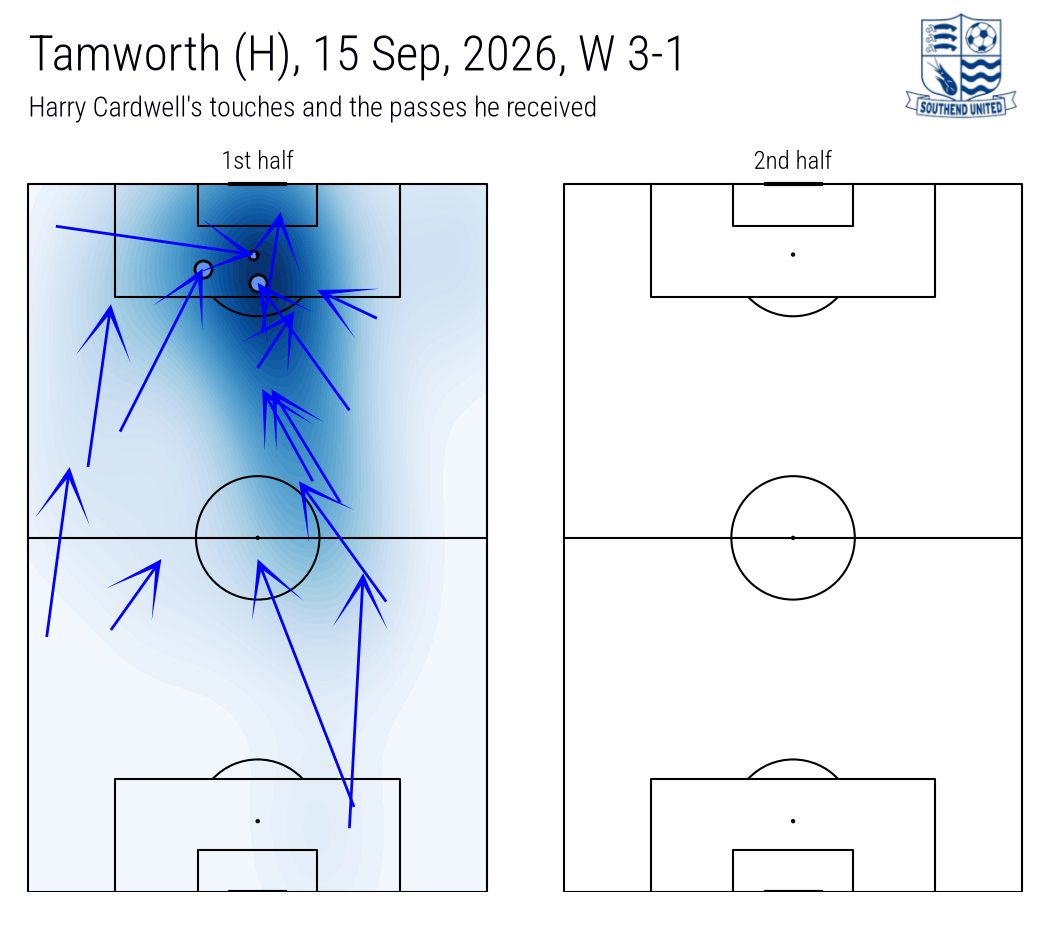

(<Figure size 1171.32x1000 with 5 Axes>,
 {'pitch': array([<Axes: >, <Axes: >], dtype=object),
  'title': <Axes: >,
  'endnote': <Axes: >},
 VerticalPitch(pitch_type='wyscout', half=False, pitch_color='white', line_color='black', linewidth=1.5, line_zorder=2, linestyle=None, stripe=False, stripe_color='#c2d59d', stripe_zorder=0.6, pad_left=4, pad_right=4, pad_bottom=0.0, pad_top=12.952380952380954, positional=False, positional_zorder=0.8, positional_linewidth=1.5, positional_linestyle=None, positional_color='#eadddd', positional_alpha=1, shade_middle=False, shade_color='#f2f2f2', shade_alpha=1, shade_zorder=0.7, pitch_length=None, pitch_width=None, goal_type='line', goal_alpha=1, line_alpha=1, label=False, tick=False, axis=False, spot_scale=0.024, spot_type='circle'), corner_arcs=False))

In [6]:
match.action_map(SOUTHEND, MATCH_ID, player_id=H_CARDWELL, passes_received_by=H_CARDWELL,
                 subtitle=["Harry Cardwell's touches and the passes he received"])

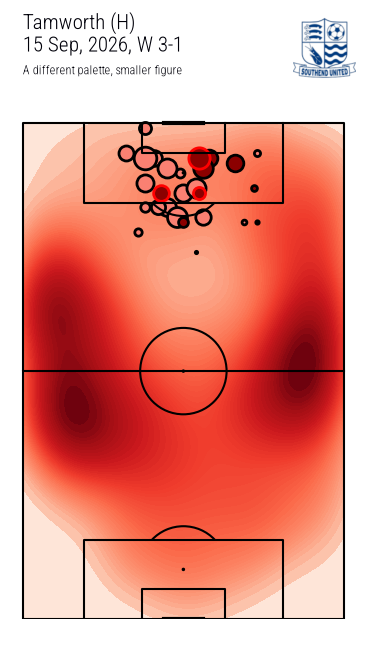

(<Figure size 394.052x700 with 4 Axes>,
 {'pitch': <Axes: >, 'title': <Axes: >, 'endnote': <Axes: >},
 VerticalPitch(pitch_type='wyscout', half=False, pitch_color='white', line_color='black', linewidth=1.5, line_zorder=2, linestyle=None, stripe=False, stripe_color='#c2d59d', stripe_zorder=0.6, pad_left=4, pad_right=4, pad_bottom=0.0, pad_top=12.952380952380954, positional=False, positional_zorder=0.8, positional_linewidth=1.5, positional_linestyle=None, positional_color='#eadddd', positional_alpha=1, shade_middle=False, shade_color='#f2f2f2', shade_alpha=1, shade_zorder=0.7, pitch_length=None, pitch_width=None, goal_type='line', goal_alpha=1, line_alpha=1, label=False, tick=False, axis=False, spot_scale=0.024, spot_type='circle'), corner_arcs=False))

In [7]:
match.action_map(SOUTHEND, MATCH_ID, split_halves=False, cmap="Reds", shot_colors=("darkred", "salmon"),
                 fig_height=7, subtitle=["A different palette, smaller figure"])

## `average_positions_map` - where everyone stood

Mean position per player from their events and the passes they received. Starters in the
first colour, substitutes in the second, shirt numbers on the markers.

| argument | effect |
|---|---|
| `split="halves"` | a pitch per half (default); `None` for the whole match |
| `filter_fn` | any predicate on an event splits the match into accepted / rejected, titled with `titles` |
| `colors`, `text_colors` | marker and number colours for (starters, substitutes) |

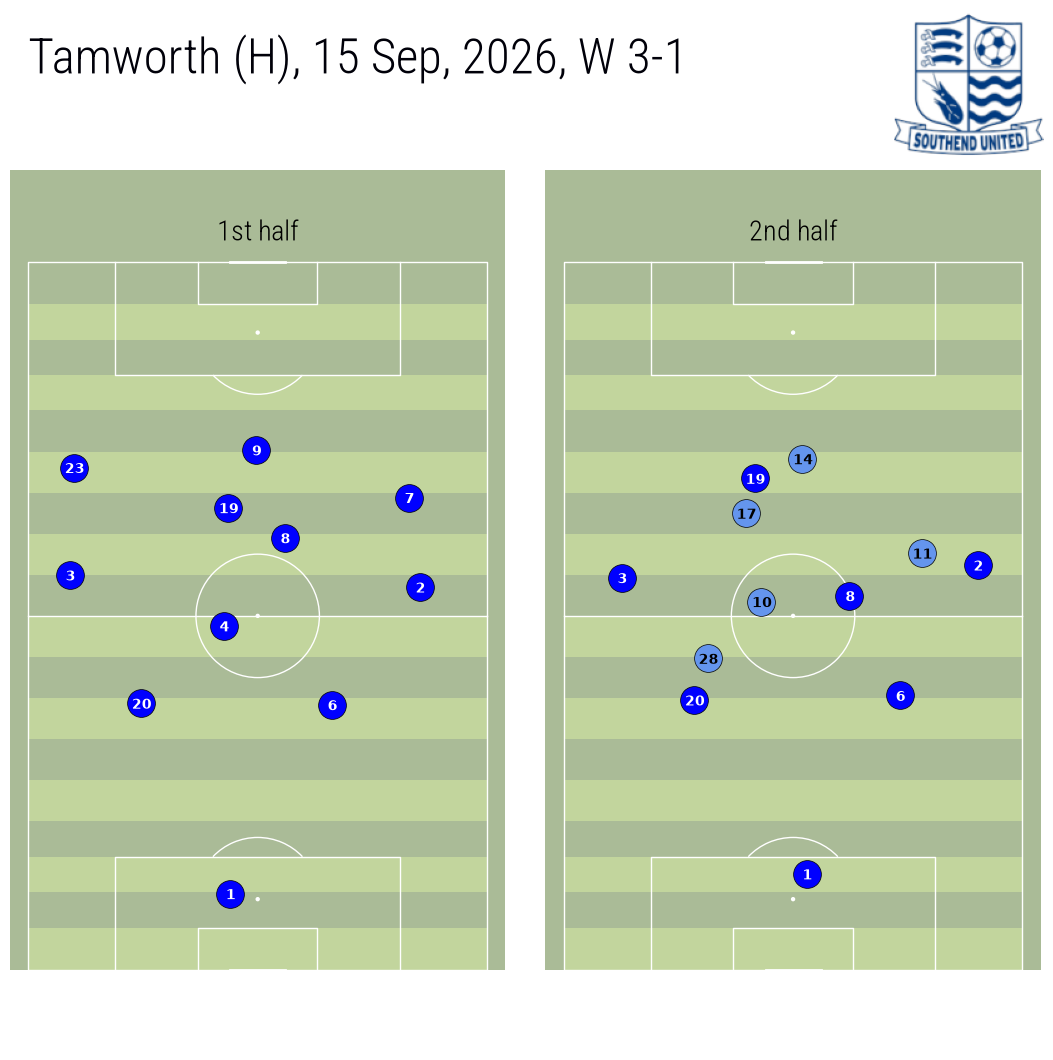

(<Figure size 1171.32x1000 with 5 Axes>,
 {'pitch': array([<Axes: >, <Axes: >], dtype=object),
  'title': <Axes: >,
  'endnote': <Axes: >},
 VerticalPitch(pitch_type='wyscout', half=False, pitch_color='#aabb97', line_color='white', linewidth=1, line_zorder=2, linestyle=None, stripe=True, stripe_color='#c2d59d', stripe_zorder=0.6, pad_left=4, pad_right=4, pad_bottom=0.0, pad_top=12.952380952380954, positional=False, positional_zorder=0.8, positional_linewidth=1, positional_linestyle=None, positional_color='#eadddd', positional_alpha=1, shade_middle=False, shade_color='#f2f2f2', shade_alpha=1, shade_zorder=0.7, pitch_length=None, pitch_width=None, goal_type='line', goal_alpha=1, line_alpha=1, label=False, tick=False, axis=False, spot_scale=0.024, spot_type='circle'), corner_arcs=False))

In [8]:
match.average_positions_map(SOUTHEND, MATCH_ID)

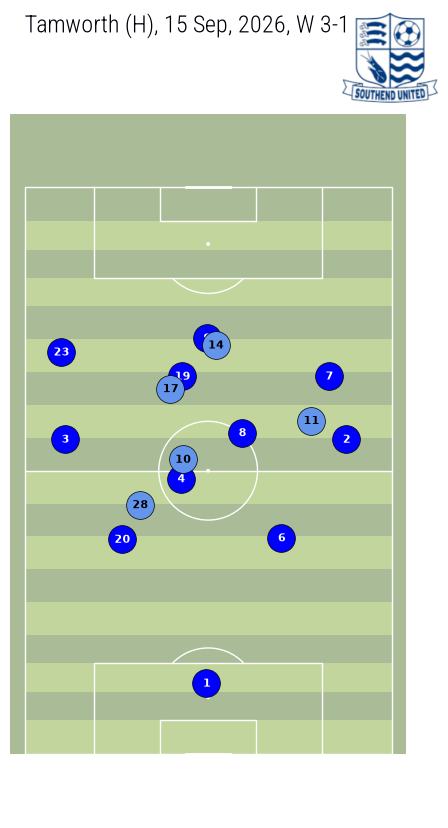

(<Figure size 450.345x800 with 4 Axes>,
 {'pitch': <Axes: >, 'title': <Axes: >, 'endnote': <Axes: >},
 VerticalPitch(pitch_type='wyscout', half=False, pitch_color='#aabb97', line_color='white', linewidth=1, line_zorder=2, linestyle=None, stripe=True, stripe_color='#c2d59d', stripe_zorder=0.6, pad_left=4, pad_right=4, pad_bottom=0.0, pad_top=12.952380952380954, positional=False, positional_zorder=0.8, positional_linewidth=1, positional_linestyle=None, positional_color='#eadddd', positional_alpha=1, shade_middle=False, shade_color='#f2f2f2', shade_alpha=1, shade_zorder=0.7, pitch_length=None, pitch_width=None, goal_type='line', goal_alpha=1, line_alpha=1, label=False, tick=False, axis=False, spot_scale=0.024, spot_type='circle'), corner_arcs=False))

In [9]:
match.average_positions_map(SOUTHEND, MATCH_ID, split=None, fig_height=8)

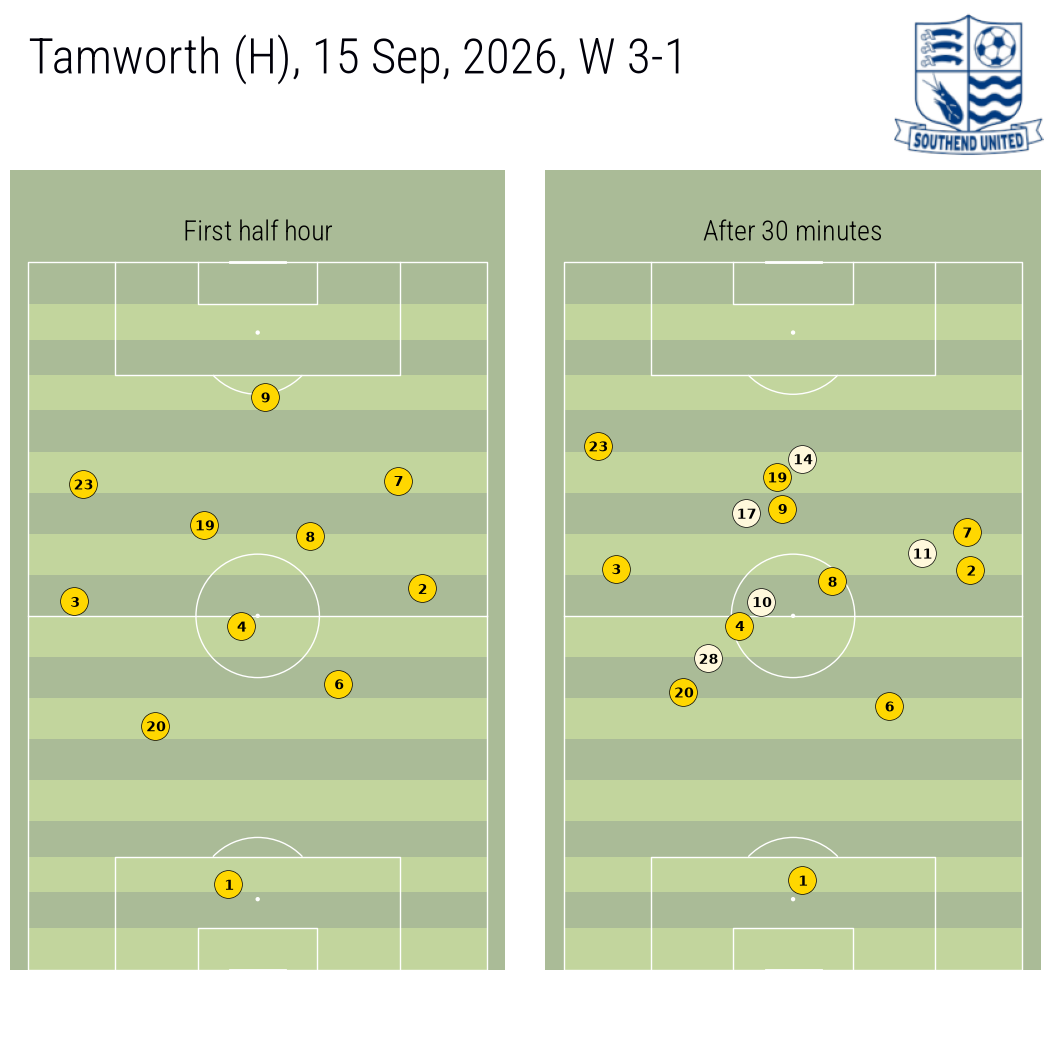

(<Figure size 1171.32x1000 with 5 Axes>,
 {'pitch': array([<Axes: >, <Axes: >], dtype=object),
  'title': <Axes: >,
  'endnote': <Axes: >},
 VerticalPitch(pitch_type='wyscout', half=False, pitch_color='#aabb97', line_color='white', linewidth=1, line_zorder=2, linestyle=None, stripe=True, stripe_color='#c2d59d', stripe_zorder=0.6, pad_left=4, pad_right=4, pad_bottom=0.0, pad_top=12.952380952380954, positional=False, positional_zorder=0.8, positional_linewidth=1, positional_linestyle=None, positional_color='#eadddd', positional_alpha=1, shade_middle=False, shade_color='#f2f2f2', shade_alpha=1, shade_zorder=0.7, pitch_length=None, pitch_width=None, goal_type='line', goal_alpha=1, line_alpha=1, label=False, tick=False, axis=False, spot_scale=0.024, spot_type='circle'), corner_arcs=False))

In [10]:
match.average_positions_map(SOUTHEND, MATCH_ID, filter_fn=lambda e: e["minute"] < 30,
                            titles=("First half hour", "After 30 minutes"),
                            colors=("gold", "cornsilk"), text_colors=("black", "black"))

## `final_third_passes` - passes in the attacking third

Every pass started in the final third as an arrow over a touch heat map. Accurate passes take
the first colour, inaccurate the second; a pass in a goal-scoring move is thick and red.

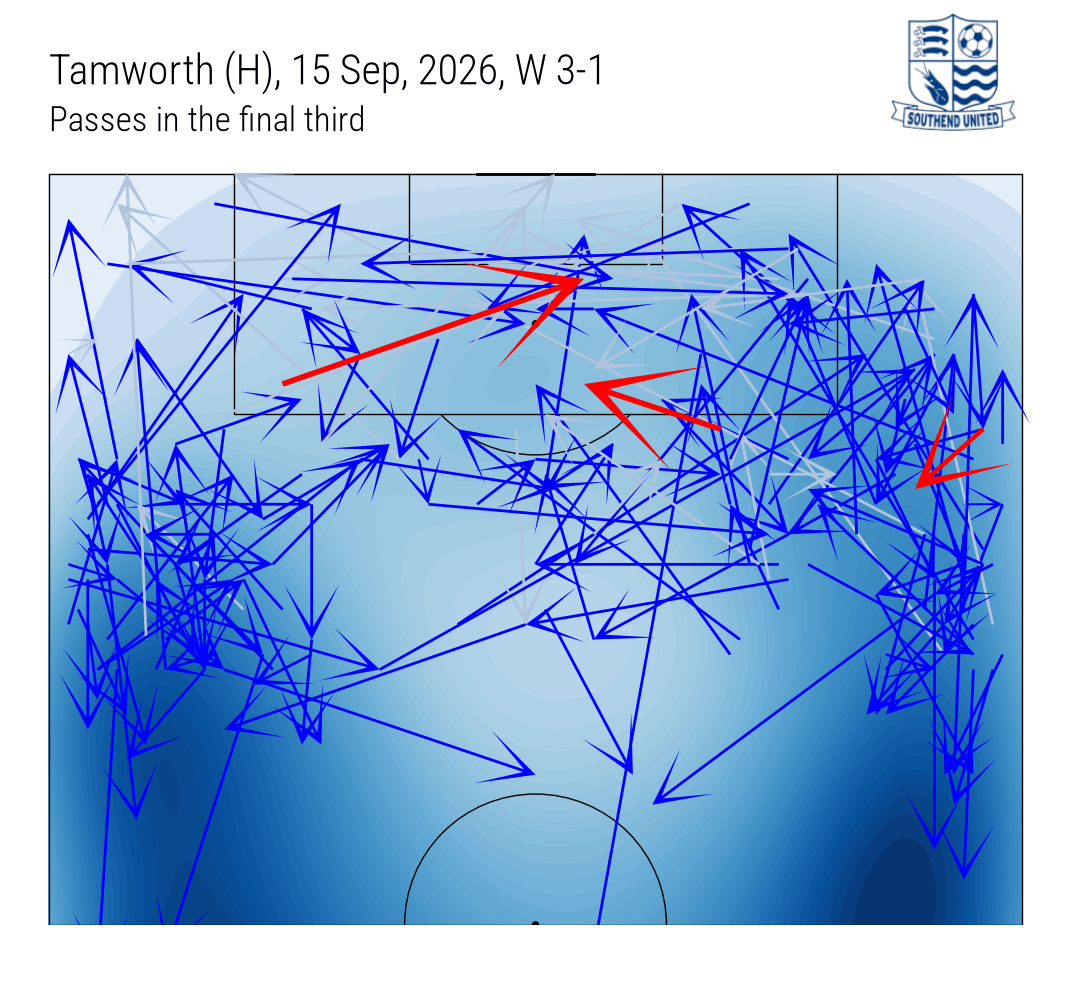

(<Figure size 1194.34x1000 with 4 Axes>,
 {'pitch': <Axes: >, 'title': <Axes: >, 'endnote': <Axes: >},
 VerticalPitch(pitch_type='wyscout', half=True, pitch_color='white', line_color='black', linewidth=1, line_zorder=2, linestyle=None, stripe=False, stripe_color='#c2d59d', stripe_zorder=0.6, pad_left=4, pad_right=4, pad_bottom=0.0, pad_top=3.2380952380952386, positional=False, positional_zorder=0.8, positional_linewidth=1, positional_linestyle=None, positional_color='#eadddd', positional_alpha=1, shade_middle=False, shade_color='#f2f2f2', shade_alpha=1, shade_zorder=0.7, pitch_length=None, pitch_width=None, goal_type='line', goal_alpha=1, line_alpha=1, label=False, tick=False, axis=False, spot_scale=0.024, spot_type='circle'), corner_arcs=False))

In [11]:
match.final_third_passes(SOUTHEND, MATCH_ID)

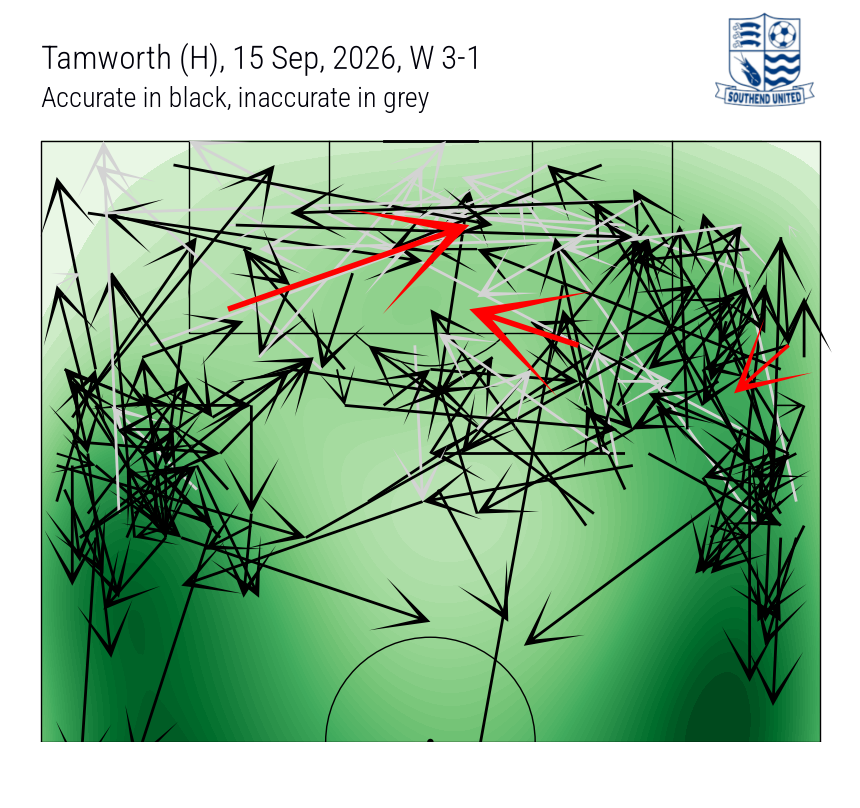

(<Figure size 955.472x800 with 4 Axes>,
 {'pitch': <Axes: >, 'title': <Axes: >, 'endnote': <Axes: >},
 VerticalPitch(pitch_type='wyscout', half=True, pitch_color='white', line_color='black', linewidth=1, line_zorder=2, linestyle=None, stripe=False, stripe_color='#c2d59d', stripe_zorder=0.6, pad_left=4, pad_right=4, pad_bottom=0.0, pad_top=3.2380952380952386, positional=False, positional_zorder=0.8, positional_linewidth=1, positional_linestyle=None, positional_color='#eadddd', positional_alpha=1, shade_middle=False, shade_color='#f2f2f2', shade_alpha=1, shade_zorder=0.7, pitch_length=None, pitch_width=None, goal_type='line', goal_alpha=1, line_alpha=1, label=False, tick=False, axis=False, spot_scale=0.024, spot_type='circle'), corner_arcs=False))

In [12]:
match.final_third_passes(SOUTHEND, MATCH_ID, pass_colors=("black", "lightgrey"), cmap="Greens",
                         subtitle=["Accurate in black, inaccurate in grey"], fig_height=8)

## `xg_race` - cumulative xG through the match

Both sides' xG stepping up at every attempt (penalties included), with the totals at the end.
Pass `ax=` to draw into your own axes - here two matches side by side.

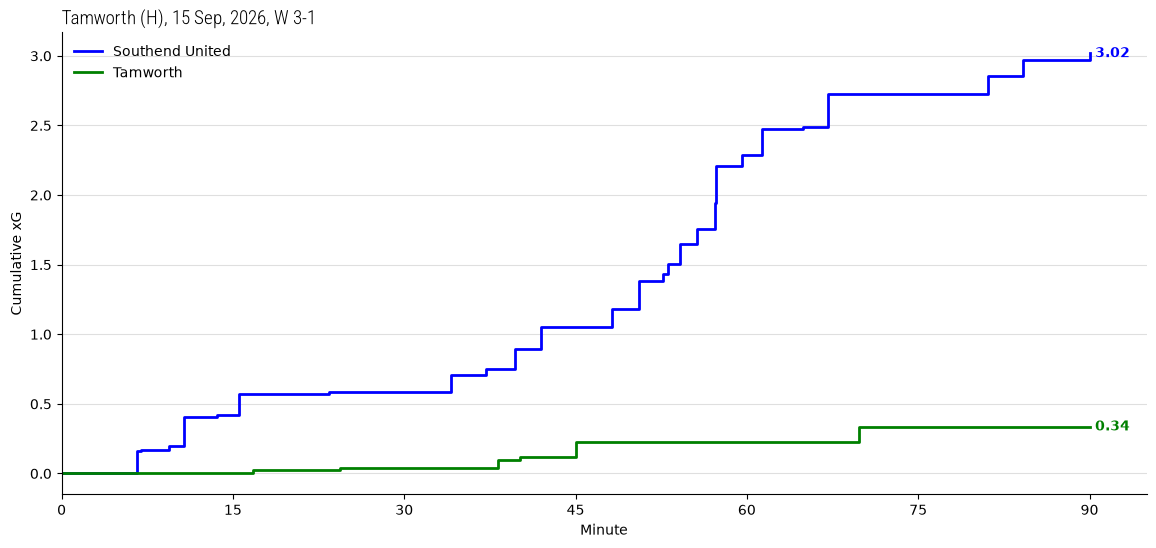

<Axes: title={'left': 'Tamworth (H), 15 Sep, 2026, W 3-1'}, xlabel='Minute', ylabel='Cumulative xG'>

In [13]:
match.xg_race(SOUTHEND, MATCH_ID)

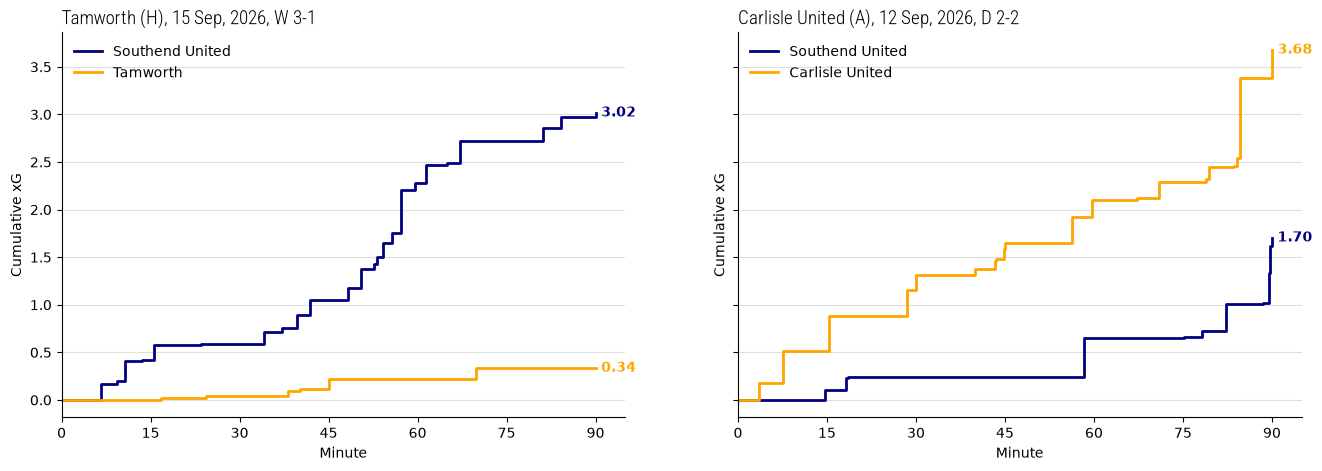

<Axes: title={'left': 'Carlisle United (A), 12 Sep, 2026, D 2-2'}, xlabel='Minute', ylabel='Cumulative xG'>

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5), sharey=True)
match.xg_race(SOUTHEND, MATCH_ID, colours=("navy", "orange"), ax=axes[0], show=False)
match.xg_race(SOUTHEND, OTHER_MATCH, colours=("navy", "orange"), ax=axes[1])

## `shot_map` - attempts on a striped pitch

Attempts on the classic green half pitch, red for goals. `both_teams=True` adds the
opposition's beside ours; `include_pens` adds penalties.

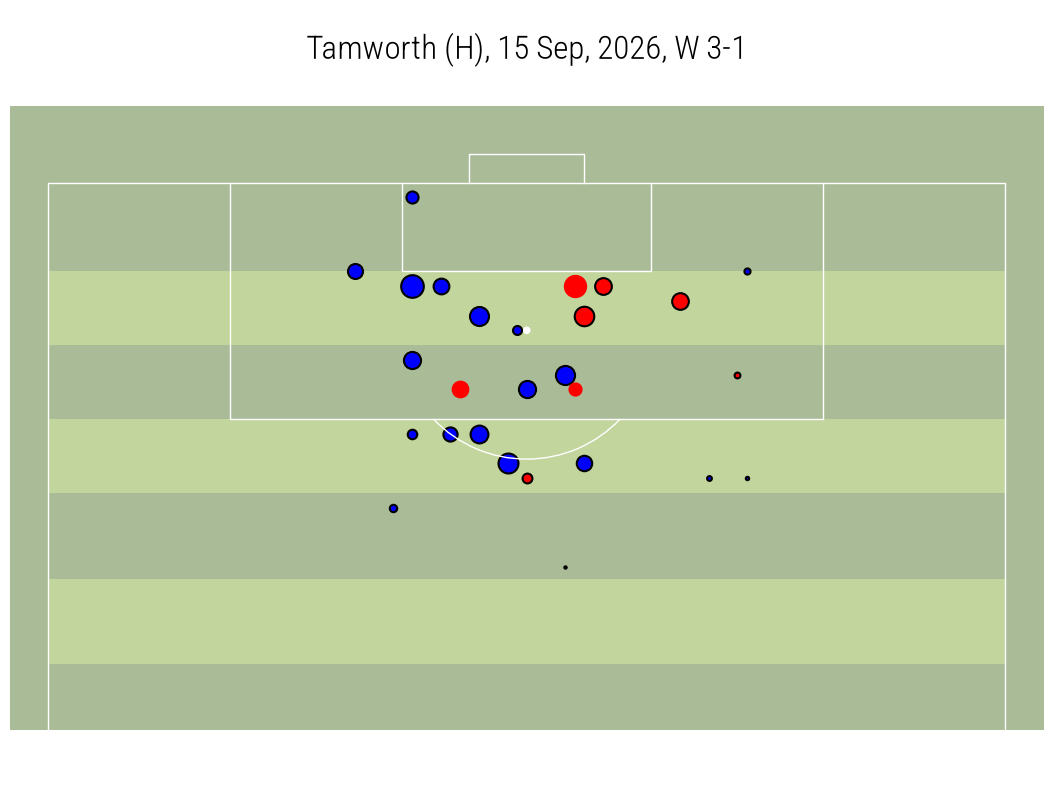

(<Figure size 1174.46x800 with 3 Axes>,
 {'pitch': <Axes: >, 'title': <Axes: >, 'endnote': <Axes: >},
 VerticalPitch(pitch_type='wyscout', half=True, pitch_color='#aabb97', line_color='white', linewidth=1, line_zorder=2, linestyle=None, stripe=True, stripe_color='#c2d59d', stripe_zorder=0.6, pad_left=4, pad_right=4, pad_bottom=-12.952380952380954, pad_top=5.180952380952381, positional=False, positional_zorder=0.8, positional_linewidth=1, positional_linestyle=None, positional_color='#eadddd', positional_alpha=1, shade_middle=False, shade_color='#f2f2f2', shade_alpha=1, shade_zorder=0.7, pitch_length=None, pitch_width=None, goal_type='box', goal_alpha=1, line_alpha=1, label=False, tick=False, axis=False, spot_scale=0.024, spot_type='circle'), corner_arcs=False))

In [15]:
match.shot_map(SOUTHEND, MATCH_ID)

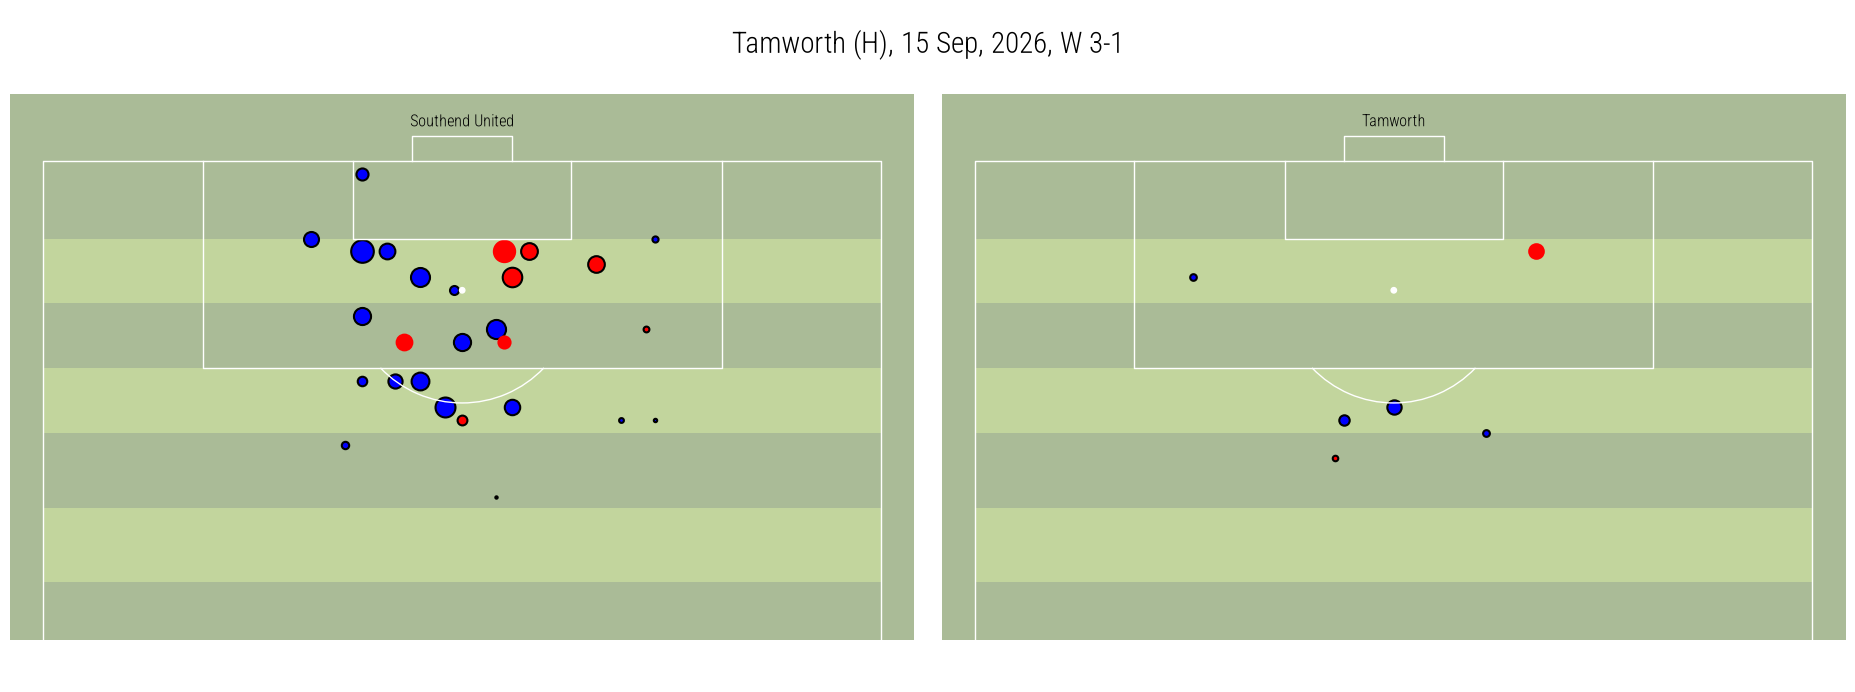

(<Figure size 2086.33x700 with 4 Axes>,
 {'pitch': array([<Axes: >, <Axes: >], dtype=object),
  'title': <Axes: >,
  'endnote': <Axes: >},
 VerticalPitch(pitch_type='wyscout', half=True, pitch_color='#aabb97', line_color='white', linewidth=1, line_zorder=2, linestyle=None, stripe=True, stripe_color='#c2d59d', stripe_zorder=0.6, pad_left=4, pad_right=4, pad_bottom=-12.952380952380954, pad_top=5.180952380952381, positional=False, positional_zorder=0.8, positional_linewidth=1, positional_linestyle=None, positional_color='#eadddd', positional_alpha=1, shade_middle=False, shade_color='#f2f2f2', shade_alpha=1, shade_zorder=0.7, pitch_length=None, pitch_width=None, goal_type='box', goal_alpha=1, line_alpha=1, label=False, tick=False, axis=False, spot_scale=0.024, spot_type='circle'), corner_arcs=False))

In [16]:
match.shot_map(SOUTHEND, MATCH_ID, both_teams=True, include_pens=True, fig_height=7)

## `player_action_map` - one player in one match

The player's touch heat map with, optionally, their passes, their crosses or the passes they
received as arrows. `period="1H"` or `"2H"` limits it to one half;
`highlight_first_half=True` colours first-half arrows red.

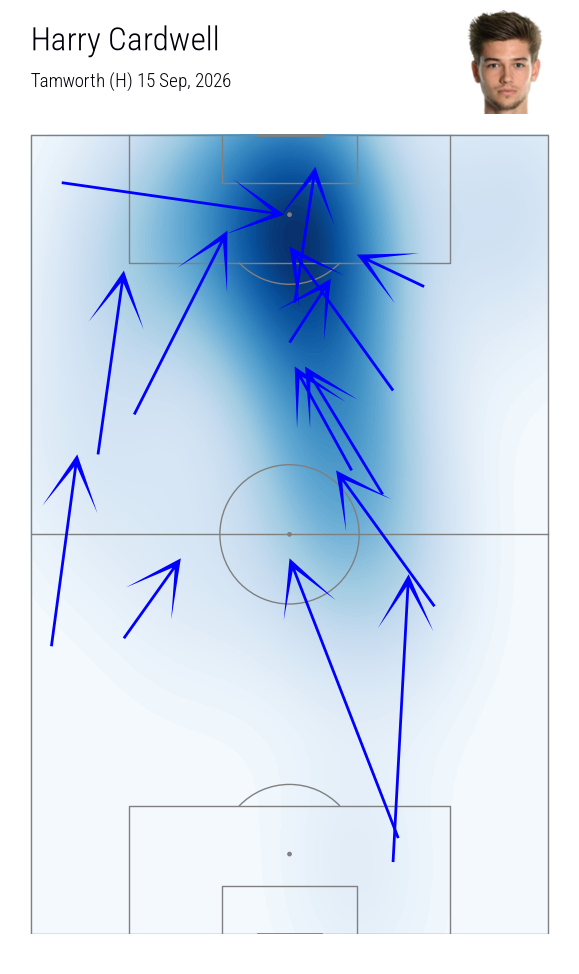

(<Figure size 635.283x1000 with 4 Axes>,
 {'pitch': <Axes: >, 'title': <Axes: >, 'endnote': <Axes: >},
 VerticalPitch(pitch_type='wyscout', half=False, pitch_color='white', line_color='grey', linewidth=1, line_zorder=2, linestyle=None, stripe=False, stripe_color='#c2d59d', stripe_zorder=0.6, pad_left=4, pad_right=4, pad_bottom=0.0, pad_top=2.5904761904761906, positional=False, positional_zorder=0.8, positional_linewidth=1, positional_linestyle=None, positional_color='#eadddd', positional_alpha=1, shade_middle=False, shade_color='#f2f2f2', shade_alpha=1, shade_zorder=0.7, pitch_length=None, pitch_width=None, goal_type='line', goal_alpha=1, line_alpha=1, label=False, tick=False, axis=False, spot_scale=0.024, spot_type='circle'), corner_arcs=False))

In [17]:
match.player_action_map(H_CARDWELL, SOUTHEND, MATCH_ID, show_passes_received=True, fig_height=10)

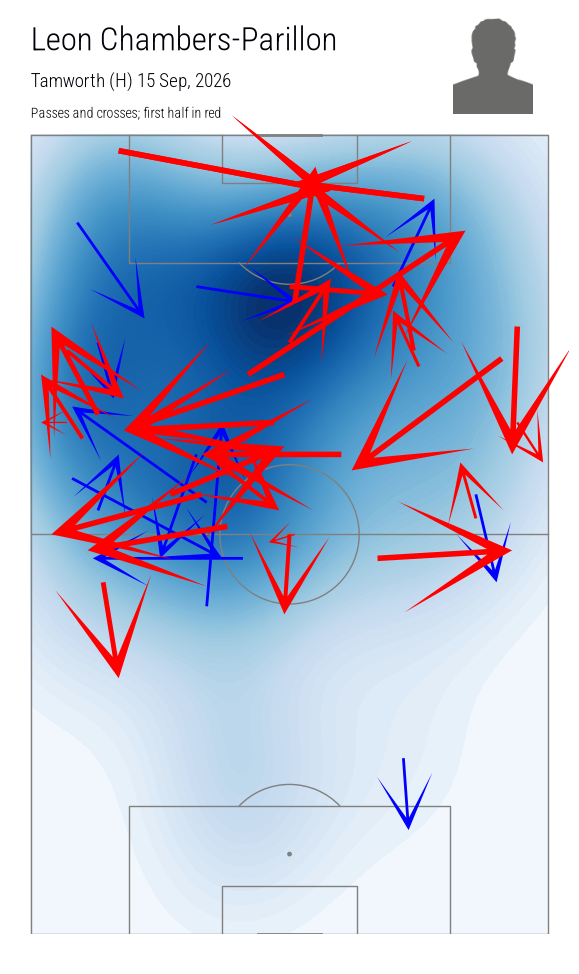

(<Figure size 635.283x1000 with 4 Axes>,
 {'pitch': <Axes: >, 'title': <Axes: >, 'endnote': <Axes: >},
 VerticalPitch(pitch_type='wyscout', half=False, pitch_color='white', line_color='grey', linewidth=1, line_zorder=2, linestyle=None, stripe=False, stripe_color='#c2d59d', stripe_zorder=0.6, pad_left=4, pad_right=4, pad_bottom=0.0, pad_top=2.5904761904761906, positional=False, positional_zorder=0.8, positional_linewidth=1, positional_linestyle=None, positional_color='#eadddd', positional_alpha=1, shade_middle=False, shade_color='#f2f2f2', shade_alpha=1, shade_zorder=0.7, pitch_length=None, pitch_width=None, goal_type='line', goal_alpha=1, line_alpha=1, label=False, tick=False, axis=False, spot_scale=0.024, spot_type='circle'), corner_arcs=False))

In [18]:
match.player_action_map(L_CHAMBERS_PARILLON, SOUTHEND, MATCH_ID, show_passes=True, show_crosses=True,
                        highlight_first_half=True, subtitle="Passes and crosses; first half in red", fig_height=10)

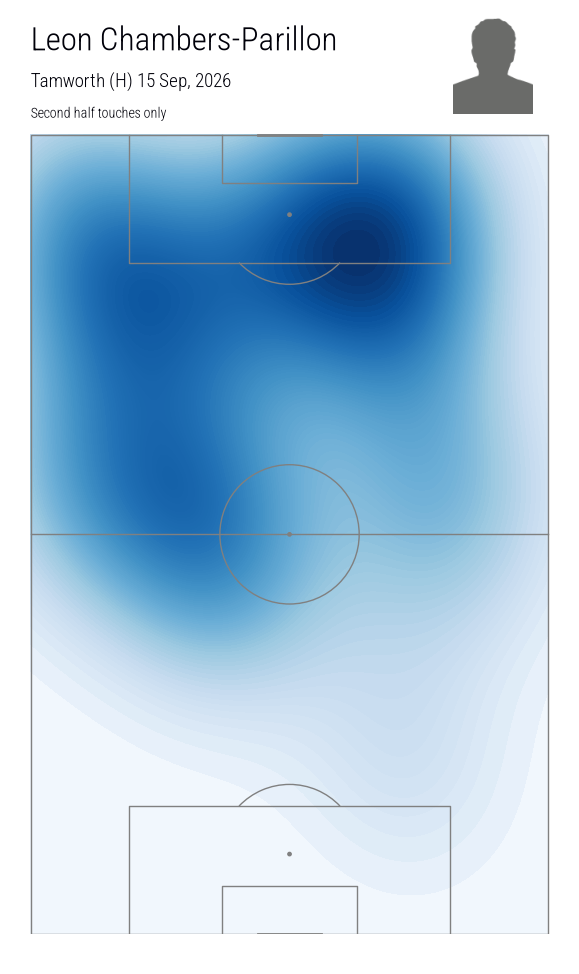

(<Figure size 635.283x1000 with 4 Axes>,
 {'pitch': <Axes: >, 'title': <Axes: >, 'endnote': <Axes: >},
 VerticalPitch(pitch_type='wyscout', half=False, pitch_color='white', line_color='grey', linewidth=1, line_zorder=2, linestyle=None, stripe=False, stripe_color='#c2d59d', stripe_zorder=0.6, pad_left=4, pad_right=4, pad_bottom=0.0, pad_top=2.5904761904761906, positional=False, positional_zorder=0.8, positional_linewidth=1, positional_linestyle=None, positional_color='#eadddd', positional_alpha=1, shade_middle=False, shade_color='#f2f2f2', shade_alpha=1, shade_zorder=0.7, pitch_length=None, pitch_width=None, goal_type='line', goal_alpha=1, line_alpha=1, label=False, tick=False, axis=False, spot_scale=0.024, spot_type='circle'), corner_arcs=False))

In [19]:
match.player_action_map(L_CHAMBERS_PARILLON, SOUTHEND, MATCH_ID, period="2H", subtitle="Second half touches only", fig_height=10)

## `pass_matrix_chart` - who passes to whom

Completed passes between team mates, passers down the side and recipients along the top.
Give `match_ids` for particular matches or `season_id` for the whole season.

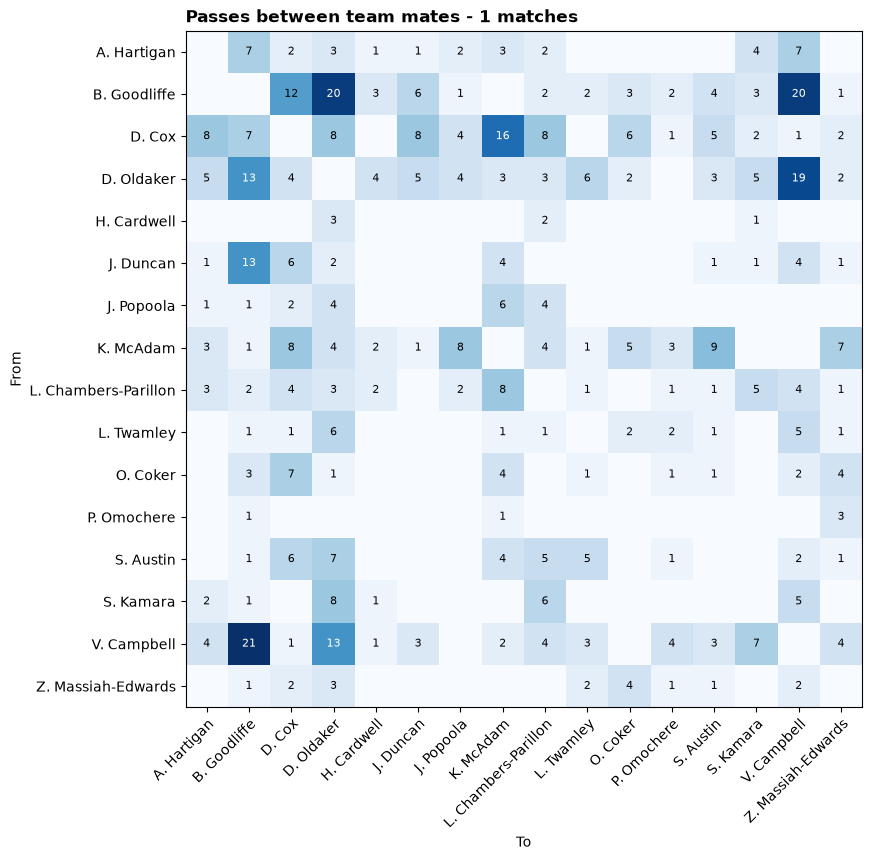

(<Figure size 880x880 with 1 Axes>,
 <Axes: title={'left': 'Passes between team mates - 1 matches'}, xlabel='To', ylabel='From'>)

In [20]:
match.pass_matrix_chart(SOUTHEND, match_ids=[MATCH_ID])

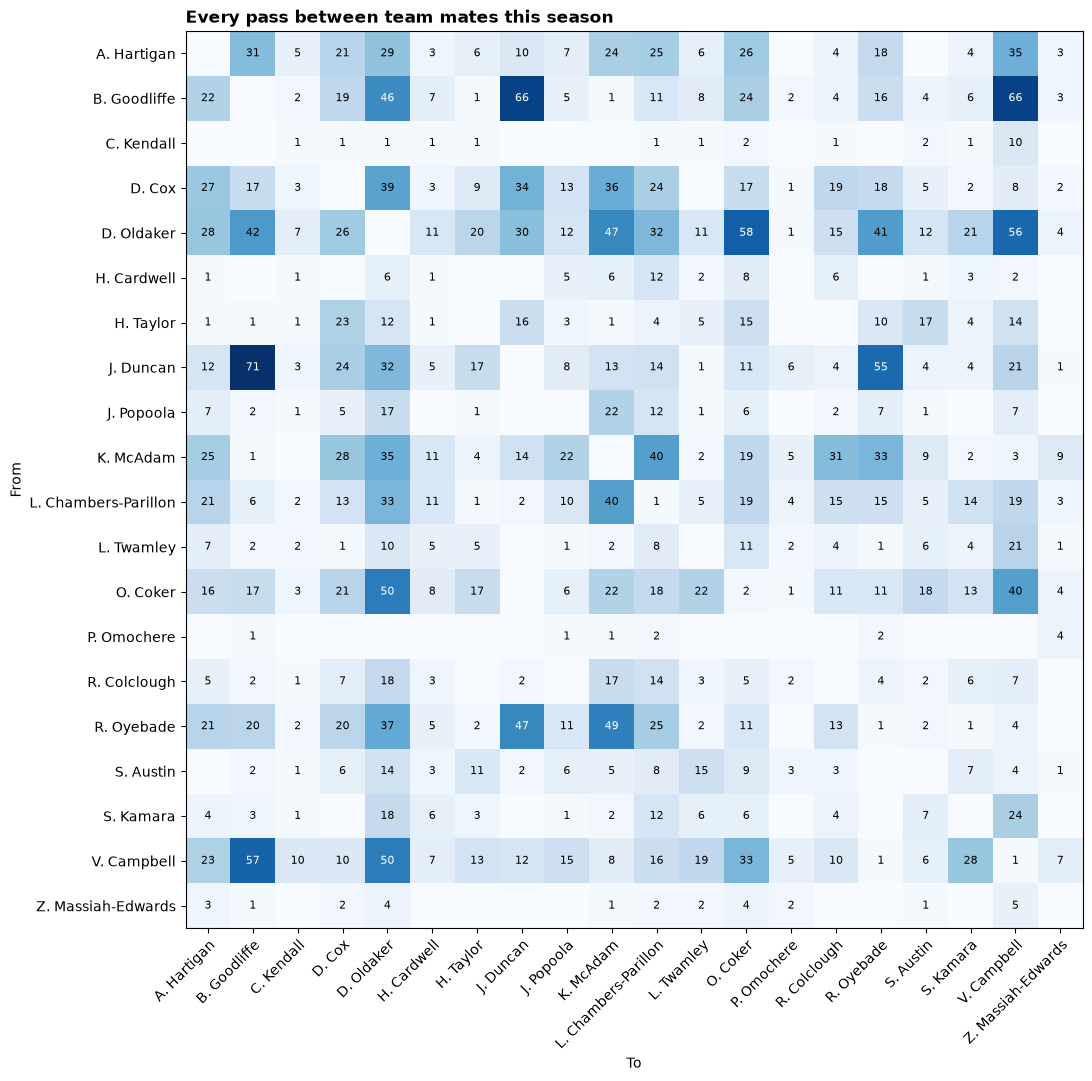

(<Figure size 1100x1100 with 1 Axes>,
 <Axes: title={'left': 'Every pass between team mates this season'}, xlabel='To', ylabel='From'>)

In [21]:
match.pass_matrix_chart(SOUTHEND, season_id=SEASON, title="Every pass between team mates this season")

## Going under the reports: data + viz directly

The reports are short functions over two layers. `wyscout.data.match.team_match` fetches a
match once; `wyscout.data.filters` picks events out of it; `wyscout.viz.event_map` draws any
combination of heat map, attempts, arrows and marker sets on one or more pitches.

Here: every interception and foul Southend committed, split by half, drawn with the generic
`plot_event_maps`.

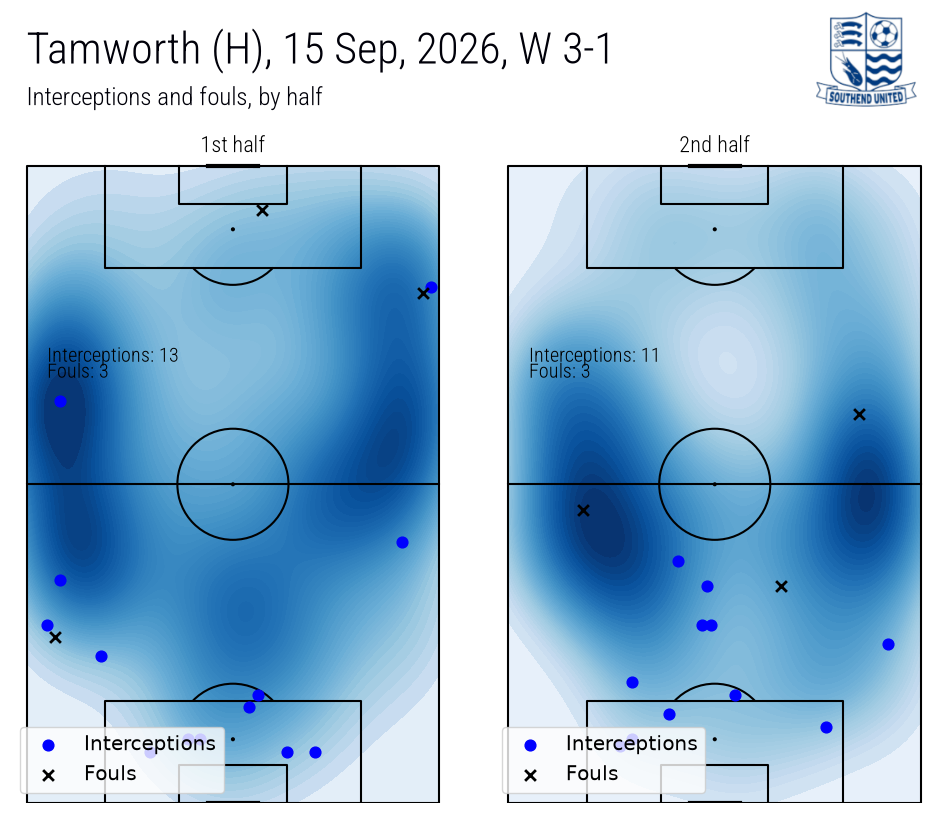

(<Figure size 1054.19x900 with 5 Axes>,
 {'pitch': array([<Axes: >, <Axes: >], dtype=object),
  'title': <Axes: >,
  'endnote': <Axes: >},
 VerticalPitch(pitch_type='wyscout', half=False, pitch_color='white', line_color='black', linewidth=1.5, line_zorder=2, linestyle=None, stripe=False, stripe_color='#c2d59d', stripe_zorder=0.6, pad_left=4, pad_right=4, pad_bottom=0.0, pad_top=12.952380952380954, positional=False, positional_zorder=0.8, positional_linewidth=1.5, positional_linestyle=None, positional_color='#eadddd', positional_alpha=1, shade_middle=False, shade_color='#f2f2f2', shade_alpha=1, shade_zorder=0.7, pitch_length=None, pitch_width=None, goal_type='line', goal_alpha=1, line_alpha=1, label=False, tick=False, axis=False, spot_scale=0.024, spot_type='circle'), corner_arcs=False))

In [22]:
from wyscout.data import filters
from wyscout.data.match import events_by_half, team_match
from wyscout.viz.event_map import EventPanel, Markers, plot_event_maps

tm = team_match(SOUTHEND, MATCH_ID)
panels = []
for half, events in zip(("1st half", "2nd half"), events_by_half(tm.team_events)):
    panels.append(EventPanel(
        title=half,
        touches=filters.locations(events),
        markers=[
            Markers(filters.locations(filters.interceptions(events)), color="blue", size=60, label="Interceptions"),
            Markers(filters.locations(filters.fouls(events)), color="black", marker="x", size=60, linewidth=2, label="Fouls"),
        ],
        stats={"Interceptions": len(filters.interceptions(events)), "Fouls": len(filters.fouls(events))},
    ))

plot_event_maps(panels, tm.summary.title(), subtitle=["Interceptions and fouls, by half"],
                header_imgs=[tm.team_badge_url], legend=True, fig_height=9)